In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV Version:", cv2.__version__)
print("NumPy Version :", np.__version__)

OpenCV Version: 4.10.0
NumPy Version : 1.26.4


/home/tanay/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


In [2]:
img = cv2.imread("../Data/Cat.jpg")

if img is None:
    print("Image not found!")
else:
    print("Image loaded successfully.")
    print("Shape :", img.shape)
    print("Data Type :", img.dtype)

Image loaded successfully.
Shape : (350, 525, 3)
Data Type : uint8


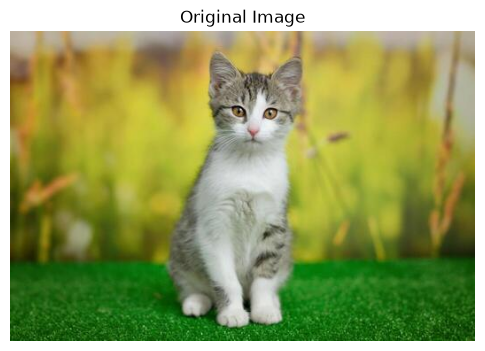

In [3]:
plt.figure(figsize=(6, 5))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")
plt.show()

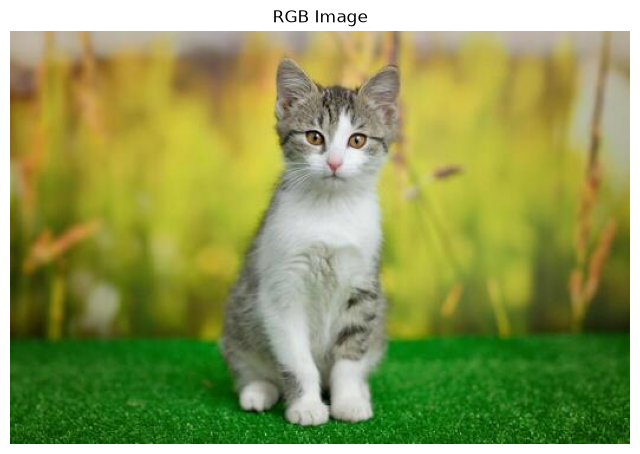

In [4]:
rgb = img[:, :, ::-1]

plt.figure(figsize=(8, 6))
plt.imshow(rgb)
plt.title("RGB Image")
plt.axis("off")
plt.show()

In [5]:
height, width, channels = img.shape[0], img.shape[1], img.shape[2]

print("Height :", height)
print("Width  :", width)
print("Channels :", channels)

Height : 350
Width  : 525
Channels : 3


In [6]:
print("Pixel Value at (100,100):")
print(np.array([img.item(100, 100, c) for c in range(3)]))

Pixel Value at (100,100):
[ 51 174 188]


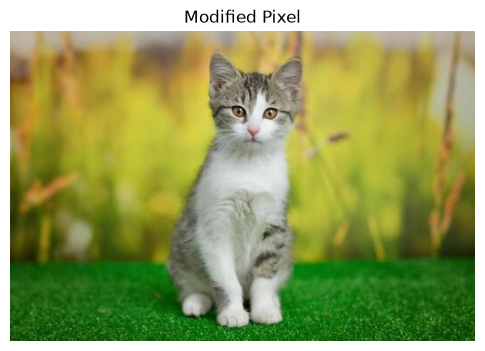

In [7]:
modified = np.copy(img)
for c, val in enumerate([0, 255, 0]):
    modified.itemset((100, 100, c), val)

plt.figure(figsize=(6, 5))
plt.imshow(cv2.cvtColor(modified, cv2.COLOR_BGR2RGB))
plt.title("Modified Pixel")
plt.axis("off")
plt.show()

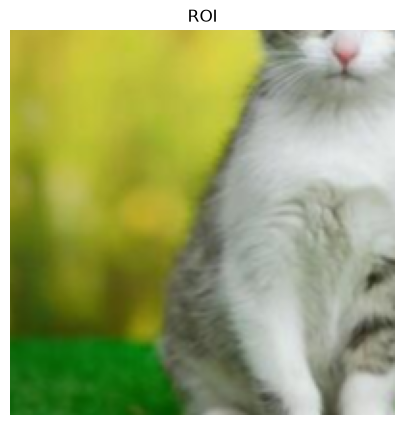

In [8]:
roi = cv2.getRectSubPix(img, (200, 200), (200, 200))

plt.figure(figsize=(6, 5))
plt.imshow(cv2.cvtColor(roi.astype(np.uint8), cv2.COLOR_BGR2RGB))
plt.title("ROI")
plt.axis("off")
plt.show()

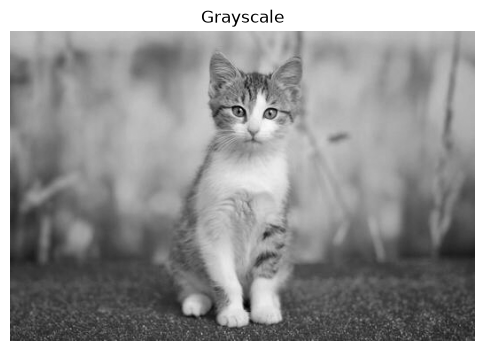

In [9]:
gray = np.dot(img[..., :3], [0.114, 0.587, 0.299]).astype(np.uint8)

plt.figure(figsize=(6, 5))
plt.imshow(gray, cmap="gray")
plt.title("Grayscale")
plt.axis("off")
plt.show()

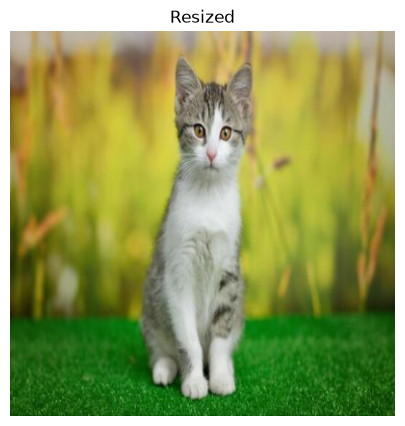

In [10]:
M = np.float32([[400 / img.shape[1], 0, 0], [0, 400 / img.shape[0], 0]])
resize = cv2.warpAffine(img, M, (400, 400))

plt.figure(figsize=(6, 5))
plt.imshow(cv2.cvtColor(resize, cv2.COLOR_BGR2RGB))
plt.title("Resized")
plt.axis("off")
plt.show()

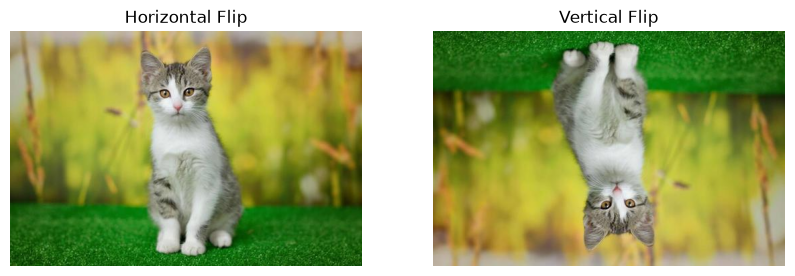

In [11]:
horizontal = np.fliplr(img)
vertical = np.flipud(img)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(cv2.cvtColor(horizontal, cv2.COLOR_BGR2RGB))
axes[0].set_title("Horizontal Flip")
axes[0].axis("off")
axes[1].imshow(cv2.cvtColor(vertical, cv2.COLOR_BGR2RGB))
axes[1].set_title("Vertical Flip")
axes[1].axis("off")
plt.show()

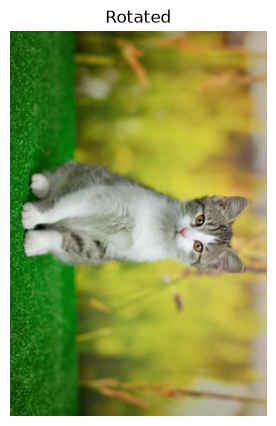

In [12]:
rotate = np.rot90(img, k=-1)

plt.figure(figsize=(6, 5))
plt.imshow(cv2.cvtColor(rotate, cv2.COLOR_BGR2RGB))
plt.title("Rotated")
plt.axis("off")
plt.show()

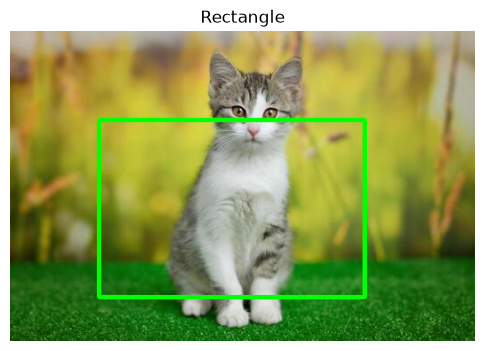

In [13]:
rectangle = img.copy()
pts = np.array([[[100, 100], [400, 100], [400, 300], [100, 300]]], dtype=np.int32)
cv2.polylines(rectangle, pts, isClosed=True, color=(0, 255, 0), thickness=3)

plt.figure(figsize=(6, 5))
plt.imshow(cv2.cvtColor(rectangle, cv2.COLOR_BGR2RGB))
plt.title("Rectangle")
plt.axis("off")
plt.show()

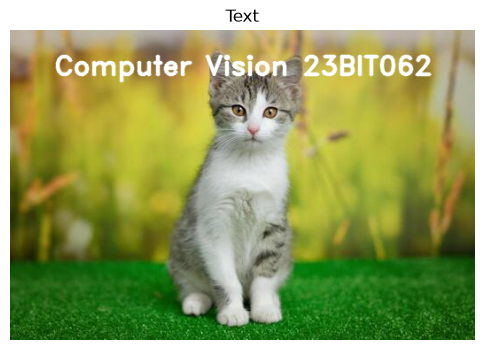

In [15]:
text = img.copy()
cv2.putText(text, "Computer Vision 23BIT062", (50, 50), cv2.FONT_HERSHEY_DUPLEX, 1, (255, 255, 255), 2, cv2.LINE_AA)

plt.figure(figsize=(6, 5))
plt.imshow(cv2.cvtColor(text, cv2.COLOR_BGR2RGB))
plt.title("Text")
plt.axis("off")
plt.show()